# **Анализ A/B-теста новой формы оплаты ЖКХ с упрощенным автозаполнением реквизитов**

**Изменение:** упрощённое автозаполнение реквизитов.  
**Период теста:** 1-30 апреля 2024 года.

**Гипотеза**: Новая форма с автозаполнением реквизитов увеличит долю успешных оплат ЖКХ.  
**Основная метрика:** конверсия из открытия формы оплаты в успешную оплату (1-4).


## **1. Загрузка данных**


In [164]:
!gdown --fuzzy "https://docs.google.com/spreadsheets/d/1eF9RXcdp_0eZ4WiopCet_VoB2e6K3Gv0/edit?usp=sharing&ouid=114804037321101504806&rtpof=true&sd=true" -O /content/Users_data.xlsx

import pandas as pd
import numpy as np
df_users=pd.read_excel('/content/Users_data.xlsx',sheet_name='Пользователи')
df_payments=pd.read_excel('/content/Users_data.xlsx',sheet_name='Платежи')
print(df_users.head())

df_users.tail()

Downloading...
From: https://drive.google.com/uc?id=1eF9RXcdp_0eZ4WiopCet_VoB2e6K3Gv0
To: /content/Users_data.xlsx
100% 175k/175k [00:00<00:00, 5.19MB/s]
   user_id group  age    city device_type
0     1001     A   31  Москва         ios
1     1002     A   31  Москва         ios
2     1003     A   25  Москва     android
3     1004     A   20  Москва         ios
4     1005     A   34  Москва         ios


,user_id,group,age,city,device_type
1499,2500,B,39,Москва,ios
1500,9001,NaN,25,Москва,ios
1501,9002,A,-5,СПб,android
1502,9003,B,150,Регион,ios
1503,9004,A,30,NaN,android


## **2. EDA и очистка данных**

Сначала проверяем таблицу пользователей: типы данных, структура таблицы, пропуски, дубликаты, распределение по группам и аномальные значения.


### **2.1. Таблица Users**


In [165]:
df_users.info()
df_users.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1504 entries, 0 to 1503
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   user_id      1504 non-null   int64 
 1   group        1503 non-null   object
 2   age          1504 non-null   int64 
 3   city         1503 non-null   object
 4   device_type  1504 non-null   object
dtypes: int64(2), object(3)
memory usage: 58.9+ KB


,user_id,age
count,1504.000000,1504.000000
mean,1769.787234,32.745346
std,571.592080,8.410915
min,1001.000000,-5.000000
25%,1376.750000,27.000000
50%,1752.500000,33.000000
75%,2128.250000,38.000000
max,9004.000000,150.000000


In [166]:
# Посмотрим распределение пользователей и проверим на NaN и дубли
print(df_users.isna().sum()) #пропуски
print('\nДубликаты','='*70,sep='\n')
print('Полные дубликаты строк: ',df_users.duplicated().sum())
print('Дубликаты user_id',df_users['user_id'].duplicated().sum())
print('\nКоличество пользователей в группах','='*70,df_users['group'].value_counts(dropna=False),sep='\n')
print('\nКоличество пользоваткелей по городам','='*70,df_users['city'].value_counts(dropna=False),sep='\n')
print('\nКоличество пользователей по типам устройств','='*70,df_users['device_type'].value_counts(dropna=False),sep='\n')



user_id        0
group          1
age            0
city           1
device_type    0
dtype: int64

Дубликаты
Полные дубликаты строк:  0
Дубликаты user_id 0

Количество пользователей в группах
group
A      752
B      751
NaN      1
Name: count, dtype: int64

Количество пользоваткелей по городам
city
Москва    595
Регион    514
СПб       394
NaN         1
Name: count, dtype: int64

Количество пользователей по типам устройств
device_type
android    777
ios        727
Name: count, dtype: int64


In [167]:
#Выведем строки с подозрительными значениями
print(df_users[df_users['group'].isna()
    |df_users['city'].isna()
    |(df_users['age']<0)
    |(df_users['age']>100)
])
users_copy=df_users.copy()
# Пользователя без группы исключаем из набора
# его нельзя однозначно отнести к A или B
# Аномальные значения возраста заменяем на NaN
# Пропуск city оставляем, но не используем в анализе по городам
users_copy=users_copy.dropna(subset=['group'])#удалим строку с пустой группой
#заменяем аномальные значения возраста на NaN
users_copy.loc[(users_copy['age']<0)|(users_copy['age']>100),'age']=np.nan
users_copy['age'] = users_copy['age'].astype('Int64')
print('\n',users_copy[
    users_copy['group'].isna()
    |users_copy['city'].isna()
    |(users_copy['age']< 0)
    |(users_copy['age']>100)
])
print(users_copy[users_copy['age'].isna()])

      user_id group  age    city device_type
1500     9001   NaN   25  Москва         ios
1501     9002     A   -5     СПб     android
1502     9003     B  150  Регион         ios
1503     9004     A   30     NaN     android

       user_id group  age city device_type
1503     9004     A   30  NaN     android
      user_id group   age    city device_type
1501     9002     A  <NA>     СПб     android
1502     9003     B  <NA>  Регион         ios


### **2.2 Таблица Payments**

In [168]:
df_payments.info()

print('\nКоличество пропусков','='*70,df_payments.isna().sum(),sep='\n')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2661 entries, 0 to 2660
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   payment_id       2661 non-null   int64         
 1   user_id          2660 non-null   float64       
 2   group            2661 non-null   object        
 3   step1_opened     2661 non-null   datetime64[ns]
 4   step2_entered    2256 non-null   datetime64[ns]
 5   step3_confirmed  1719 non-null   datetime64[ns]
 6   step4_success    1522 non-null   datetime64[ns]
dtypes: datetime64[ns](4), float64(1), int64(1), object(1)
memory usage: 145.7+ KB

Количество пропусков
payment_id            0
user_id               1
group                 0
step1_opened          0
step2_entered       405
step3_confirmed     942
step4_success      1139
dtype: int64


In [169]:
df_payments.head(10)


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00
5,5006,1004.0,A,2024-04-24 17:26:00,2024-04-24 17:27:00,2024-04-24 17:30:00,2024-04-24 17:36:00
6,5007,1005.0,A,2024-04-11 21:10:00,2024-04-11 21:11:00,NaT,NaT
7,5008,1006.0,A,2024-04-12 13:48:00,2024-04-12 13:52:00,2024-04-12 13:55:00,2024-04-12 14:00:00
8,5009,1007.0,A,2024-04-09 11:28:00,2024-04-09 11:30:00,2024-04-09 11:35:00,2024-04-09 11:42:00
9,5010,1007.0,A,2024-04-08 06:54:00,NaT,NaT,NaT


In [170]:
df_payments.tail(10)


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
2651,7652,2497.0,B,2024-04-22 04:27:00,NaT,NaT,NaT
2652,7653,2498.0,B,2024-04-02 18:28:00,2024-04-02 18:29:00,2024-04-02 18:32:00,2024-04-02 18:35:00
2653,7654,2499.0,B,2024-04-03 10:43:00,2024-04-03 10:47:00,2024-04-03 10:50:00,2024-04-03 10:55:00
2654,7655,2499.0,B,2024-04-14 19:30:00,2024-04-14 19:31:00,2024-04-14 19:38:00,2024-04-14 19:44:00
2655,7656,2499.0,B,2024-04-24 20:54:00,2024-04-24 21:00:00,2024-04-24 21:03:00,2024-04-24 21:08:00
2656,7657,2500.0,B,2024-04-11 07:01:00,2024-04-11 07:04:00,NaT,NaT
2657,7658,9004.0,A,2024-04-05 16:14:00,2024-04-05 16:15:00,2024-04-05 16:18:00,2024-04-05 16:23:00
2658,99001,1005.0,A,2024-04-05 10:30:00,2024-04-05 10:33:00,2024-04-05 10:38:00,2024-04-05 10:39:00
2659,99002,1010.0,B,2024-04-08 14:20:00,2024-04-08 14:23:00,2024-04-08 14:28:00,2024-04-08 14:29:00
2660,99003,NaN,A,2024-04-12 09:15:00,NaT,NaT,NaT


In [171]:
print(f'Полные дубликаты строк: {df_payments.duplicated().sum()}','='*70,sep='\n')
print(f'Дубликаты в payment_id: {df_payments['payment_id'].duplicated().sum()}','='*70,sep='\n')
print(f'Количество уникальных пользователей в payments: {df_payments['user_id'].nunique()}','='*70,sep='\n')
print(f'Выборка повторных попыток оплаты пользователей: {df_payments['user_id'].value_counts().head(10)}','='*70,sep='\n')


Полные дубликаты строк: 0
Дубликаты в payment_id: 0
Количество уникальных пользователей в payments: 1501
Выборка повторных попыток оплаты пользователей: user_id
1381.0    4
1321.0    4
2434.0    4
1323.0    4
2490.0    4
1409.0    4
2467.0    4
1489.0    4
1492.0    4
2412.0    4
Name: count, dtype: int64


In [172]:
print('Количество уникальных пользователей по группам Paymants:','='*70,df_payments.groupby('group')['user_id'].nunique(),sep='\n')
print('\nВсего количество попыток платежей','='*70,df_payments['group'].value_counts(),sep='\n')

print('\nКоличество уникальных пользователей по группам Users:','='*70,users_copy['group'].value_counts(),sep='\n')
user_not_in_paymants=users_copy[~users_copy['user_id'].isin(df_payments['user_id'].dropna())]
print('\nПользователи users которых нет в paymants','='*70,user_not_in_paymants,sep='\n')

Количество уникальных пользователей по группам Paymants:
group
A    751
B    751
Name: user_id, dtype: int64

Всего количество попыток платежей
group
B    1352
A    1309
Name: count, dtype: int64

Количество уникальных пользователей по группам Users:
group
A    752
B    751
Name: count, dtype: int64

Пользователи users которых нет в paymants
      user_id group   age    city device_type
1501     9002     A  <NA>     СПб     android
1502     9003     B  <NA>  Регион         ios


In [173]:
check_groups = df_payments.merge(
    users_copy[['user_id', 'group']],
    on='user_id',
    how='left',
    suffixes=('_payment', '_user')
)
print('Несоответствие назначения группы между таблицами','='*70,sep='\n')

check_groups[check_groups['group_payment'] != check_groups['group_user']][
['user_id', 'group_payment', 'group_user']].drop_duplicates()


Несоответствие назначения группы между таблицами


,user_id,group_payment,group_user
2659,1010.0,B,A
2660,NaN,A,NaN


In [174]:
print(df_payments['user_id'].notna())
print(df_payments['user_id'].isin(df_users['user_id']))

0        True
1        True
2        True
3        True
4        True
        ...  
2656     True
2657     True
2658     True
2659     True
2660    False
Name: user_id, Length: 2661, dtype: bool
0        True
1        True
2        True
3        True
4        True
        ...  
2656     True
2657     True
2658     True
2659     True
2660    False
Name: user_id, Length: 2661, dtype: bool


In [175]:
payments_copy=df_payments.copy()
payments_copy=payments_copy.dropna(subset=['user_id'])
payments_copy['user_id']=payments_copy['user_id'].astype('Int64')
payments_copy=payments_copy.drop(columns='group')
payments_copy = payments_copy.merge(users_copy[['user_id', 'group']],on='user_id',how='inner')
check_groups = payments_copy.merge(
    df_users[['user_id', 'group']],
    on='user_id',
    how='left',
    suffixes=('_payment', '_user')
)
check_groups[check_groups['group_payment'] != check_groups['group_user']][
['user_id', 'group_payment', 'group_user']].drop_duplicates()


,user_id,group_payment,group_user


In [176]:
print('Количество исходных строк Payments:', len(df_payments))
print('Количество строк после очистки Payments:', len(payments_copy))
print('Удалено строк Payments:', len(df_payments) - len(payments_copy))
print('Количество исходных строк Users:', len(df_users))
print('Количество строк после очистки Users:', len(users_copy))
print('Удалено строк Users:', len(df_users) - len(users_copy))

Количество исходных строк Payments: 2661
Количество строк после очистки Payments: 2660
Удалено строк Payments: 1
Количество исходных строк Users: 1504
Количество строк после очистки Users: 1503
Удалено строк Users: 1


### Результаты очистки

В ходе первичного анализа были проверены структура таблиц Users и Payments, пропущенные значения, дубликаты и аномалии.

При очистке данных:

* Из Users удалён один пользователь без назначения группы A/B (1 504 - 1 503).

* В Payments удалена одна запись без user_id (2 661 - 2 660).

* Обнаружено несоответствие экспериментальной группы пользователя 1010 между таблицами. Группа исправлена по данным Users.

* Некорректные значения возраста (−5 и 150 лет) заменены на пропуски.

* Выявлены два пользователя (9002 и 9003), отсутствующие в Payments. Они сохранены в Users, но не будут учитываться при расчёте конверсии, поскольку не открывали форму оплаты.

**Итог**: после очистки в таблице Users осталось 1 503 пользователя, из которых 1 501 имеет записи о попытках оплаты. Подготовленные данные используются для дальнейшей проверки эксперимента и анализа пользовательской воронки.



## 3. Проверка корректности воронки
Проверяем:
* Временной период теста
* Целостность воронки
* Временная последовательность шагов воронки


In [177]:
#Длительность теста 1-30 апреля 2024
date_steps = ['step1_opened','step2_entered','step3_confirmed','step4_success']

all_dates = pd.concat(
    [payments_copy[col] for col in date_steps],
    ignore_index=True
)

print('Минимальная дата:', all_dates.min())
print('Максимальная дата:', all_dates.max())

print('Даты вне периода:',
    (all_dates<'2024-04-01').any()or(all_dates>='2024-05-01').any())

Минимальная дата: 2024-04-01 00:19:00
Максимальная дата: 2024-04-30 23:30:00
Даты вне периода: False


In [178]:
# Проверим целостность воронки: нет ли случаев, когда последующий шаг есть без предыдущего
bad_steps = payments_copy[
    (payments_copy['step1_opened'].isna()&
     payments_copy['step2_entered'].notna())
    |
    (payments_copy['step2_entered'].isna()&
     payments_copy['step3_confirmed'].notna())
    |
    (payments_copy['step3_confirmed'].isna()&
     payments_copy['step4_success'].notna())
]


print(f'Количество строк в Payments с нарушенной последовательностью шагов: {len(bad_steps)}')


Количество строк в Payments с нарушенной последовательностью шагов: 0


In [179]:
# Проверим корректность временной последовательности шагов
bad_time = payments_copy[
    (
        payments_copy['step2_entered'].notna()
        & (payments_copy['step2_entered'] < payments_copy['step1_opened'])
    )
    |
    (
        payments_copy['step3_confirmed'].notna()
        & (payments_copy['step3_confirmed'] < payments_copy['step2_entered'])
    )
    |
    (
        payments_copy['step4_success'].notna()
        & (payments_copy['step4_success'] < payments_copy['step3_confirmed'])
    )
]

print(f'Количество строк в Payments с нарушенной временной последовательностью шагов: {len(bad_time)}')

Количество строк в Payments с нарушенной временной последовательностью шагов: 0


### Результаты проверки корректности воронки
* Период эксперимента: события вне периода отсутствуют.
* Целостность воронки: 0 аномалий.
* Временная последовательность шагов: 0 аномалий.

## **4. Проверка SRM и распределения признаков между группами**

Проверяем:
*   Распределение A/B относительно ожидаемого 50/50
*   Распределение пользователей по устройствам и городам
*   Возрастные характеристики пользователей двух групп




In [180]:
#проверим распределение групп, относительно ожидаемого 50/50
from scipy.stats import chisquare
group_counts = users_copy['group'].value_counts().sort_index()
#H0: пользователи распределяются между A и B в ожидаемом соотношении 50/50
#H1: фактическое распределение не соответствует 50/50

#не отвергаем H0
#Нет статистических оснований считать, что распределение A/B нарушено
observed = group_counts.values # реальные размеры
expected = [group_counts.sum() / 2] * 2 #ожидаемые размеры

chi2_stat, srm_pvalue = chisquare(
    f_obs=observed,
    f_exp=expected
)
#При p-value>=0.05 оснований считать распределение групп аномальным нет

print('Критерий согласия Хи-квадрат Пирсона'.center(70),'='*70,sep='\n')
print('Наблюдаемые размеры групп A и B:', *observed)
print('Ожидаемые размеры групп A и B:', *expected)
print('χ²:', chi2_stat.round(5))
print('p-value:', srm_pvalue)

                 Критерий согласия Хи-квадрат Пирсона                 
Наблюдаемые размеры групп A и B: 752 751
Ожидаемые размеры групп A и B: 751.5 751.5
χ²: 0.00067
p-value: 0.979421561620276


In [181]:
device_balance = (
pd.crosstab(
        users_copy['group'],
        users_copy['device_type'],
        normalize='index'
    ) * 100
).round(2)


print('Распределение по устройствам между группами в %:','='*45,sep='\n')
device_balance

Распределение по устройствам между группами в %:


device_type,android,ios
group,,
A,54.26,45.74
B,49.13,50.87


In [182]:
city_balance = (
    pd.crosstab(
        users_copy['group'],
        users_copy['city'],
        normalize='index'
    ) * 100
).round(2)


print('Распределение по городам между группами %:','='*45,sep='\n')
city_balance

Распределение по городам между группами %:


city,Москва,Регион,СПб
group,,,
A,38.35,35.69,25.97
B,40.75,32.76,26.50


In [183]:
age_balance = (
    users_copy
    .groupby('group')['age']
    .agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(2)
)


print('Возрастные характеристики:','='*30,sep='\n')
age_balance
#группы очень похожи не только по среднему возрасту но и по разбросу

Возрастные характеристики:


,count,mean,median,std,min,max
group,,,,,,
A,751,32.74,32.0,7.82,20,60
B,750,32.65,33.0,7.78,20,60


In [184]:
from scipy.stats import chi2_contingency

# проверка по Критерию независимости Хи-квадрат, по типу устройств

#H0: тип устройства не зависит от группы А или В
#H1: между типом устройства и группой А или В существует статистически значимая связь
device_table = pd.crosstab(
    users_copy['group'],
    users_copy['device_type']
)



chi2_dev, p_value_dev, dof_dev, expected = chi2_contingency(device_table)
expected_df=pd.DataFrame(expected, index=device_table.index,columns=device_table.columns).round(2)
print('\nОжидаемые значения:','='*30, sep='\n')
display(expected_df)

print('Реальные значения','='*30,sep='\n')
display(device_table)
print('='*30)
print('Критерий независимости Хи-квадрат по устройствам'.center(70),'='*70,sep='\n')
print('\nχ²:', chi2_dev.round(2))
print('p-value:', p_value_dev.round(4))
print('Степени свободы:', dof_dev)
chi2_dev_not, p_value_dev_not, dof_dev_not, expected_not = chi2_contingency(
    device_table,
    correction=False
)
print('p_value без поравки Йетиса:',p_value_dev_not.round(3))



Ожидаемые значения:


device_type,android,ios
group,,
A,388.76,363.24
B,388.24,362.76


Реальные значения


device_type,android,ios
group,,
A,408,344
B,369,382


           Критерий независимости Хи-квадрат по устройствам           

χ²: 3.74
p-value: 0.053
Степени свободы: 1
p_value без поравки Йетиса: 0.047


In [185]:
# проверка по Критерию независимости Хи-квадрат, по городам

#H0: город пользователя не связан с его принадлежностью к группе А или В
#H1: между городом пользователя и группой А или В существует статистически значимая связь
city_table = pd.crosstab(
    users_copy['group'],
    users_copy['city']
)

chi2_city, p_value_city, dof_city, expected_city = chi2_contingency(city_table)
expected_city_df=pd.DataFrame(expected_city,index=city_table.index,columns=city_table.columns)

print('\nОжидаемые значения:','='*30, sep='\n')
display(expected_city_df)

print('Реальные значения','='*30,sep='\n')
display(city_table)
print('='*30)
print('Критерий независимости Хи-квадрат по городам'.center(70),'='*70,sep='\n')
print('\nχ²:', chi2_city.round(2))
print('p-value:', p_value_city.round(4))
print('Степени свободы:', dof_city)




Ожидаемые значения:


city,Москва,Регион,СПб
group,,,
A,297.0,257.0,197.0
B,297.0,257.0,197.0


Реальные значения


city,Москва,Регион,СПб
group,,,
A,288,268,195
B,306,246,199


             Критерий независимости Хи-квадрат по городам             

χ²: 1.53
p-value: 0.4659
Степени свободы: 2


## **4.1 Вывод:** по результатам проверок <u>*статистически значимых*</u> различий в распределении пользователей по устройствам и городам <u>*не обнаружено*</u>

*   SRM *не обнаружено*
*   Для обоих признаков *p-value > 0.05*
* Для device_type различие *пограничное (0.053)*, поэтому его стоит учитывать при интерпретации рез-ов, но на уровне знач-ти 5%-*не значимо*
Scipy по умолчанию использует поправку Йетиса, для chi2_contingency, без поправки p-value 0.047, результат чувствителен.


## **Методы:**

*   Для SRM: Критерий согласия Хи-квадрат Пирсона, т.к. сравниваем фактическое распределение с ожидаемым 50/50  
*   Для категориальных признаков(divice_type,city): Критерий независимости Пирсона Хи-квадарт



## **5. Повторные попытки и построение пользовательской воронки**

У одного пользователя может быть несколько платёжных попыток, поэтому для основной метрики агрегируем данные на уровень пользователя: шаг считается достигнутым, если пользователь дошёл до него хотя бы в одной попытке.


In [186]:
attempts_per_user = (
    payments_copy
    .groupby(['user_id', 'group'])
    .size()
    .reset_index(name='attempts')
)
print('Количество платежных попыток пользователя','='*70,sep='\n')
display(attempts_per_user.head()) #количество попыток пользователя

Количество платежных попыток пользователя


,user_id,group,attempts
0,1001,A,1
1,1002,A,1
2,1003,A,1
3,1004,A,3
4,1005,A,2


In [187]:
attempts_summary = (
    attempts_per_user
    .groupby('group')['attempts']
    .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
    .round(2)
)
print('Статистика по количеству платёжных попыток на одного пользователя','='*70, sep='\n')
attempts_summary

Статистика по количеству платёжных попыток на одного пользователя


,count,mean,median,std,min,max
group,,,,,,
A,751,1.74,1.0,0.90,1,4
B,750,1.80,2.0,0.91,1,4


In [188]:

print('Количество платёжных попыток среди пользователе в %:','='*70, sep='\n')
pd.crosstab(
    attempts_per_user['group'],
    attempts_per_user['attempts'],
    normalize='index'
).mul(100).round(2)
# в группе В немного меньше пользователей с одной попыткой оплаты
# и больше пользователей с двумя и четырьмя попытками
# однако медиана составляет 1 в A и 2 в B.
# Интерпретировать различие будем вместе с результатами воронки и конверсией

Количество платёжных попыток среди пользователе в %:


attempts,1,2,3,4
group,,,,
A,51.53,27.43,16.25,4.79
B,47.07,31.60,15.47,5.87


In [189]:
# Агрегируем попытки на уровень пользователя и строим воронку
user_funnel = (
    payments_copy
    .groupby(['user_id', 'group'])
    .agg(
        step1=('step1_opened', lambda x: x.notna().any()),
        step2=('step2_entered', lambda x: x.notna().any()),
        step3=('step3_confirmed', lambda x: x.notna().any()),
        step4=('step4_success', lambda x: x.notna().any())
    )
    .reset_index()
)
print('Воронка шагов пользователя', '='*70,sep='\n')
display(user_funnel.head(10))

Воронка шагов пользователя


,user_id,group,step1,step2,step3,step4
0,1001,A,True,True,False,False
1,1002,A,True,True,False,False
2,1003,A,True,True,False,False
3,1004,A,True,True,True,True
4,1005,A,True,True,True,True
5,1006,A,True,True,True,True
6,1007,A,True,True,True,True
7,1008,A,True,False,False,False
8,1009,A,True,True,False,False
9,1010,A,True,True,True,True


In [190]:
print('Размер user_funnel:', user_funnel.shape)

print('\nПользователи по группам:')
print(user_funnel['group'].value_counts())

Размер user_funnel: (1501, 6)

Пользователи по группам:
group
A    751
B    750
Name: count, dtype: int64


In [191]:
# Посчитаем число пользователей, достигших каждого шага
funnel_counts = (
    user_funnel
    .groupby('group')[['step1', 'step2', 'step3', 'step4']]
    .sum()
)
print('Количество пользователей достигших каждого шага','='*70,sep='\n')
display(funnel_counts)

Количество пользователей достигших каждого шага


,step1,step2,step3,step4
group,,,,
A,751,672,549,494
B,750,707,644,603


## **6. Конверсии и проверка статистической значимости**

Основная метрика бинарная: пользователь либо успешно оплатил, либо нет. Для сравнения двух независимых долей используем двухвыборочный z-тест пропорций и рассчитываем 95% доверительный интервал для разницы конверсий.


In [192]:
#Посчитаем конверсии по шагам
conversion = pd.DataFrame({
    '1-2': funnel_counts['step2'] / funnel_counts['step1'] * 100,
    '2-3': funnel_counts['step3'] / funnel_counts['step2'] * 100,
    '3-4': funnel_counts['step4'] / funnel_counts['step3'] * 100,
    '1-4': funnel_counts['step4'] / funnel_counts['step1'] * 100
}).round(2)
print('Конверсии по шагам воронки в % в сравнении с итоговой 1-4','='*70,sep='\n')
display(conversion)
print('='*70)
print(f'Абсолютный рост: {conversion['1-4']['B']-conversion['1-4']['A']:.2f} п.п.')
print(f'Относительный рост: {(conversion['1-4']['B']-conversion['1-4']['A'])/conversion['1-4']['A']*100:.2f} %')
# Группа B показывает более высокую конверсию на всех этапах воронки
# Наибольшее различие между группами наблюдается на переходе 2-3
# Статистическую значимость различия основной конверсии проверим отдельно

Конверсии по шагам воронки в % в сравнении с итоговой 1-4


,1-2,2-3,3-4,1-4
group,,,,
A,89.48,81.70,89.98,65.78
B,94.27,91.09,93.63,80.40


Абсолютный рост: 14.62 п.п.
Относительный рост: 22.23 %


In [193]:
# Проверим статистическую значимость разницы двух конверсий z-тестом пропорций
from statsmodels.stats.proportion import proportions_ztest

successes = [
    funnel_counts.loc['A', 'step4'],
    funnel_counts.loc['B', 'step4']
]

nobs = [
    funnel_counts.loc['A', 'step1'],
    funnel_counts.loc['B', 'step1']
]

z_stat, p_value = proportions_ztest(
    count=successes,
    nobs=nobs,
    alternative='two-sided'
)
print('Z-test долей для конверсий'.center(70),'='*70,sep='\n')
print('H0: конверсии в обоих группах одинаковы','H1: конверсии различаются',sep='\n')
print('\nz-statistic:', z_stat.round(2))
print('p-value:', p_value)
print('Отвергаем Н0, различие статистически значимо p-value<0,05')

                      Z-test долей для конверсий                      
H0: конверсии в обоих группах одинаковы
H1: конверсии различаются

z-statistic: -6.39
p-value: 1.7034221600819513e-10
Отвергаем Н0, различие статистически значимо p-value<0,05


In [194]:
# посчитаем 95-% доверительный интервал

p_A = funnel_counts.loc['A', 'step4'] / funnel_counts.loc['A', 'step1']
p_B = funnel_counts.loc['B', 'step4'] / funnel_counts.loc['B', 'step1']

n_A = funnel_counts.loc['A', 'step1']
n_B = funnel_counts.loc['B', 'step1']

diff = p_B - p_A

se = np.sqrt(
    p_A * (1 - p_A) / n_A
    +
    p_B * (1 - p_B) / n_B
)

z_critical = 1.96
#ДИ
ci_low = diff - z_critical * se
ci_high = diff + z_critical * se
print('95 % Доверительный интервал'.center(70),'='*70,sep='\n')
print('Разница B - A:', round(diff * 100, 2), 'п.п.')
print('95% ДИ:',round(ci_low * 100, 2),'-',round(ci_high * 100, 2),'п.п.')
print('ДИ не включает 0, различие статистически значимо')

                     95 % Доверительный интервал                      
Разница B - A: 14.62 п.п.
95% ДИ: 10.2 - 19.05 п.п.
ДИ не включает 0, различие статистически значимо


## **7. Доп. анализ конверсий по типу устройства**

Дополнительно сравниваем результат отдельно для Android и iOS, чтобы убедиться, что общий эффект не сформирован только одной платформой.


In [195]:
user_funnel_full = user_funnel.merge(
    users_copy[['user_id', 'device_type']],
    on='user_id',
    how='left'
)
device_conversion = (
    user_funnel_full
    .groupby(['device_type', 'group'])
    .agg(
        users=('user_id', 'count'),
        success=('step4', 'sum')
    )
)

device_conversion['conversion'] = (
    device_conversion['success']
    / device_conversion['users']
    * 100
).round(2)

display(device_conversion)
print('Преимущество группы B сохраняется на обоих типах устройств: общий эффект B не выглядит следствием небольшого дисбаланса групп по device_type')

users  success  conversion
device_type group                            
android     A        407      263       64.62
            B        369      295       79.95
ios         A        344      231       67.15
            B        381      308       80.84

Преимущество группы B сохраняется на обоих типах устройств: общий эффект B не выглядит следствием небольшого дисбаланса групп по device_type


## **8. Визуализация результатов**


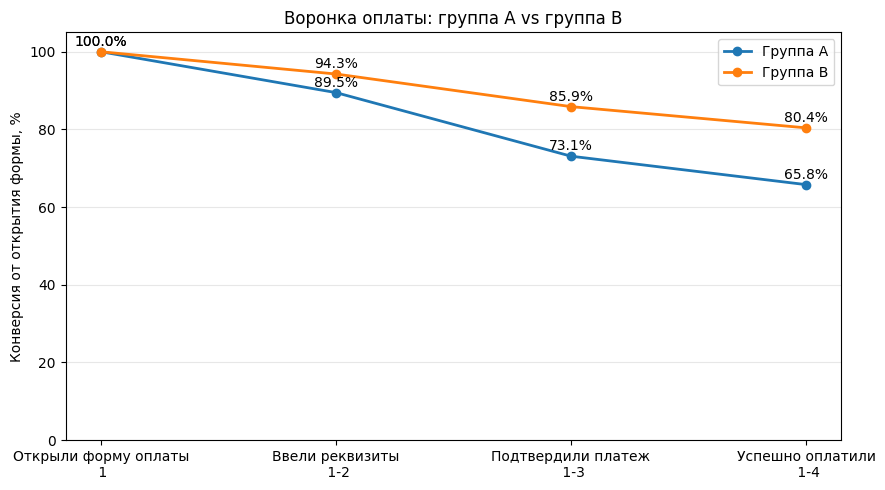

In [196]:
#Визуализируем  полученны результаты анализа
import matplotlib.pyplot as plt

# Доля пользователей, дошедших до каждого шага,
# относительно тех, кто открыл форму (step1)
funnel_percent = funnel_counts.div(
    funnel_counts['step1'],
    axis=0
) * 100

steps = [
    'Открыли форму оплаты\n 1',
    'Ввели реквизиты\n 1-2',
    'Подтвердили платеж\n 1-3',
    'Успешно оплатили\n 1-4'
]

plt.figure(figsize=(9, 5))

for group in ['A', 'B']:
    values = funnel_percent.loc[group].values

    plt.plot(
        steps,
        values,
        marker='o',
        linewidth=2,
        label=f'Группа {group}'
    )

    # Подписываем проценты возле точек
    for i, value in enumerate(values):
        plt.text(
            i,
            value + 1.5,
            f'{value:.1f}%',
            ha='center'
        )

plt.title('Воронка оплаты: группа A vs группа B')
plt.ylabel('Конверсия от открытия формы, %')
plt.ylim(0, 105)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

# Сохраняем для PDF
plt.savefig(
    '/content/funnel_ab.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

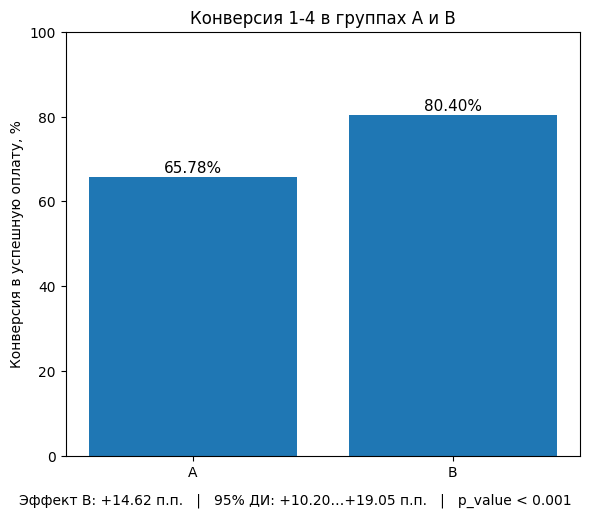

In [197]:

groups = ['A', 'B']
conversions = [p_A * 100, p_B * 100]

plt.figure(figsize=(6, 5))

bars = plt.bar(groups, conversions)

for bar, value in zip(bars, conversions):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f'{value:.2f}%',
        ha='center',
        fontsize=11
    )

plt.ylabel('Конверсия в успешную оплату, %')
plt.title('Конверсия 1-4 в группах A и B')
plt.ylim(0, 100)

# Итог выносим под график
plt.figtext(
    0.5,
    -0.02,
    'Эффект В: +14.62 п.п.   |   95% ДИ: +10.20…+19.05 п.п.   |   p_value < 0.001',
    ha='center',
    fontsize=10
)

plt.tight_layout()

plt.savefig(
    '/content/conversion_ab.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

## 9. Итоговый вывод

- Конверсия 1-4 в группе **A - 65,78%**, в группе **B - 80,40%**.
- **Абсолютный рост:** +14,62 п.п.
- **Относительный рост:** +22,2%.
- Разница статистически значима: **p_value < 0,001**.
- **95% ДИ эффекта:** [+10,20; +19,05] п.п.; интервал полностью выше нуля.
- Преимущество варианта B сохраняется отдельно на **Android** и **iOS**.

### Рекомендация

Вариант В показал **статистически значимое увеличение конверсии 1-4** на период теста (1-30 апреля 2024 года). **Однако замечено**, что медианое значение попыток оплаты у пользователей группы В=2, а у пользователей группы А =1. Причины этого различия требуют дополнительного изучения. В предоставленных данных остутствует информация о возвратах,технических ошибках и времени обработки платежей, поэтому оценить влияние новой формы на
эти показатели не предоставляется возможным.

**Рекомендовано**: перед внедрением проверить дополнительные продуктовые и технические показатели. При отсутствии их ухудшения - внедрить вариант В с последующим мониторингом коверсии 1-4, промежуточных этапов воронки и качества проведений платежей.  